# Three classic spatial derivatives and vector operations

We use `numpy` for the arrays and `matplotlib` for plots. At the end, a small `ipywidgets` slider lets you change the grid spacing and watch the error of each difference formula.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('retina')  # high-res plots

## Define a function and plot in the standard way

Let's look at the function $f(x) = \sin(x)$ and plot it from 0 to $6\pi$ using 100 points

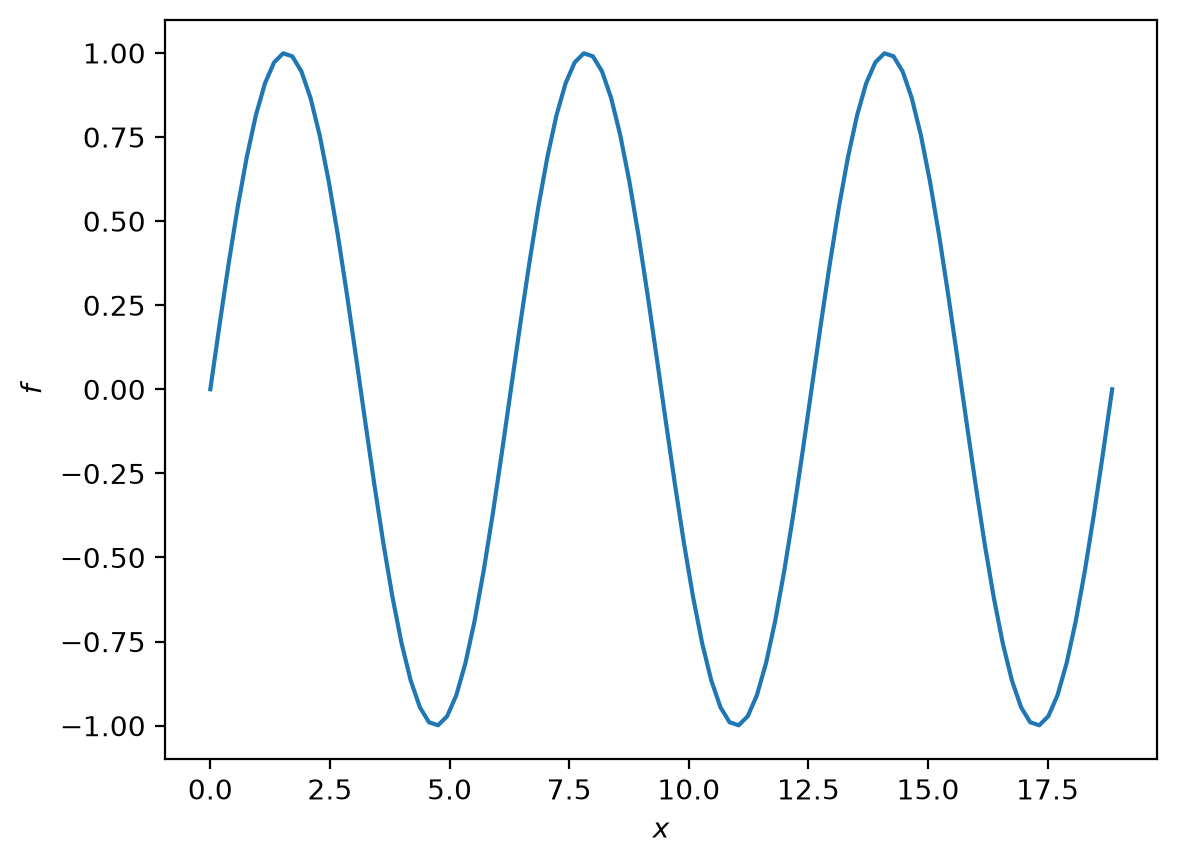

In [2]:
N = 100
x = np.linspace(0,6*np.pi,100)
f = np.sin(x)

# standard matplotlib figure
fig, ax = plt.subplots()
ax.plot(x,f)
ax.set_xlabel('$x$')
ax.set_ylabel('$f$');

## Now let's estimate the derivative of $f$ using forward difference

### Using for loops

In [3]:
# using forward difference (loop)

df_f1 = np.zeros(N)

for i in range(0,N-1):
    df_f1[i]=   (f[i+1]-f[i])/(x[i+1]-x[i])

In [4]:
# what about that last point? Recall that the last point can be accessed as [-1]
df_f1[-1]

np.float64(0.0)

In [5]:
# let's use backwards difference for that point

df_f1[-1]=(f[-1]-f[-2])/(x[-1]-x[-2])
df_f1[-1] 

np.float64(0.9939689438662982)

In [6]:
df_f1

array([ 0.99396894,  0.95804432,  0.88749347,  0.7848663 ,  0.65387202,
        0.49924509,  0.32657415,  0.14209997, -0.04751008, -0.23540298,
       -0.41478781, -0.57918113, -0.72264133, -0.8399834 , -0.92696627,
       -0.98044617, -0.99849018, -0.98044617, -0.92696627, -0.8399834 ,
       -0.72264133, -0.57918113, -0.41478781, -0.23540298, -0.04751008,
        0.14209997,  0.32657415,  0.49924509,  0.65387202,  0.7848663 ,
        0.88749347,  0.95804432,  0.99396894,  0.99396894,  0.95804432,
        0.88749347,  0.7848663 ,  0.65387202,  0.49924509,  0.32657415,
        0.14209997, -0.04751008, -0.23540298, -0.41478781, -0.57918113,
       -0.72264133, -0.8399834 , -0.92696627, -0.98044617, -0.99849018,
       -0.98044617, -0.92696627, -0.8399834 , -0.72264133, -0.57918113,
       -0.41478781, -0.23540298, -0.04751008,  0.14209997,  0.32657415,
        0.49924509,  0.65387202,  0.7848663 ,  0.88749347,  0.95804432,
        0.99396894,  0.99396894,  0.95804432,  0.88749347,  0.78

In [7]:
# note that we could have written

ilast = N-1
df_f1[ilast]=(f[ilast]-f[ilast-1])/(x[ilast]-x[ilast-1])
df_f1[ilast]

np.float64(0.9939689438662982)

### Using vector operations and array slicing

In [8]:
f1 = np.arange(0,10,0.7)
f1

array([0. , 0.7, 1.4, 2.1, 2.8, 3.5, 4.2, 4.9, 5.6, 6.3, 7. , 7.7, 8.4,
       9.1, 9.8])

In [9]:
f1[1:]

array([0.7, 1.4, 2.1, 2.8, 3.5, 4.2, 4.9, 5.6, 6.3, 7. , 7.7, 8.4, 9.1,
       9.8])

In [10]:
f1[:-1]

array([0. , 0.7, 1.4, 2.1, 2.8, 3.5, 4.2, 4.9, 5.6, 6.3, 7. , 7.7, 8.4,
       9.1])

In [11]:
f1[1:]-f1[:-1]

array([0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7,
       0.7])

In [12]:
# we can also perform a forward difference using vector operations and array slicing

df_f2 = np.zeros(N)

df_f2[:-1] = (f[1:]-f[:-1])/(x[1:]-x[:-1])
df_f2[-1] =(f[-1]-f[-2])/(x[-1]-x[-2])

### Now let's plot our FD differences against the analytic solution

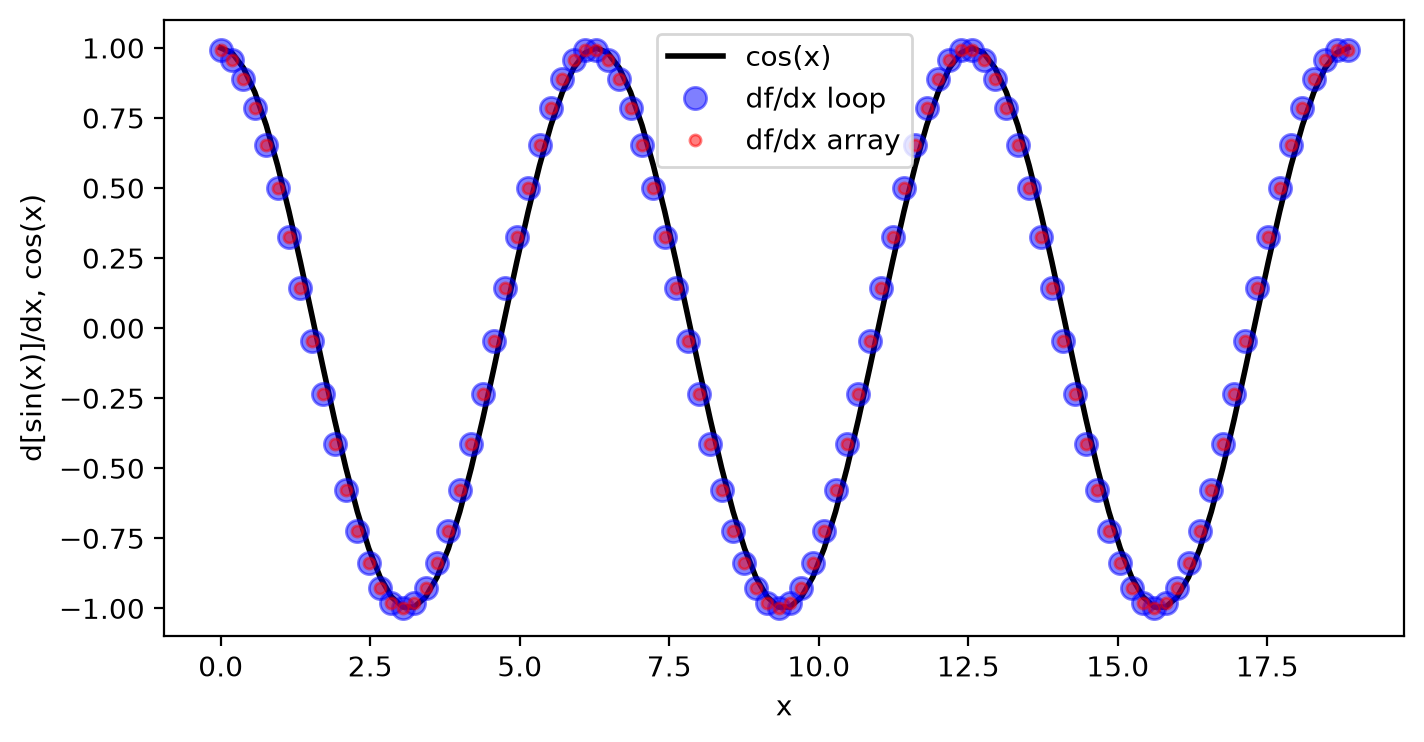

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, np.cos(x), 'k-', lw=2, label='cos(x)')
ax.plot(x, df_f1, 'o', color='blue', alpha=0.5, ms=8, label='df/dx loop')
ax.plot(x, df_f2, 'o', color='red', alpha=0.5, ms=4, label='df/dx array')
ax.set_xlabel('x'); ax.set_ylabel('d[sin(x)]/dx, cos(x)')
ax.legend();

## Estimate $df/dx$ with backward difference and central difference

In [14]:
df_f = np.zeros(N)
df_b = np.zeros(N)
df_c = np.zeros(N)

# forward difference
df_f[:-1] = (f[1:]-f[:-1])/(x[1:]-x[:-1])
#df_f2[-1] = 

# backward difference
df_b[1:] = (f[1:]-f[:-1])/(x[1:]-x[:-1])
#df_b[0] = 

# # centeral difference
# # df_c[0] 
df_c[1:-1] = (f[2:]-f[:-2])/(x[2:]-x[:-2])
# # df_c[-1]

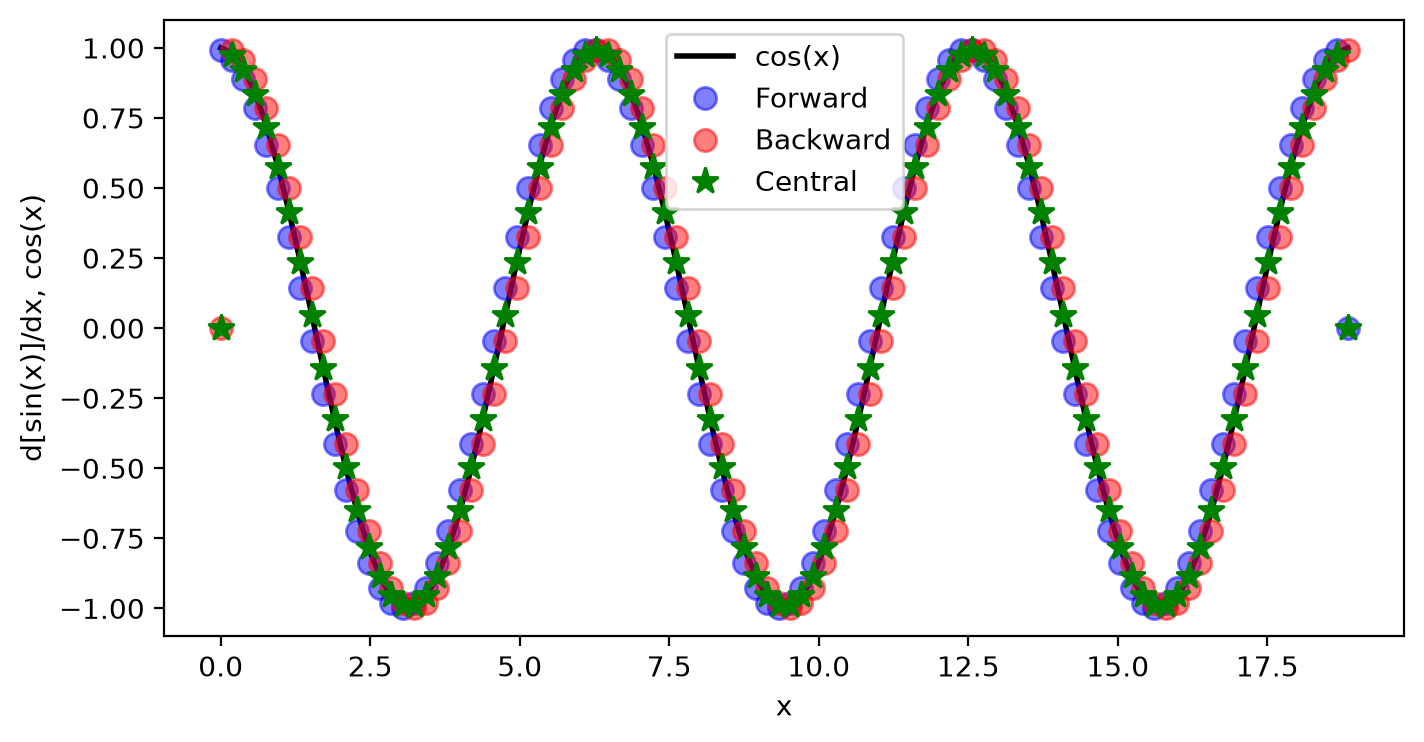

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, np.cos(x), 'k-', lw=2, label='cos(x)')
ax.plot(x, df_f, 'o', color='blue', alpha=0.5, ms=8, label='Forward')
ax.plot(x, df_b, 'o', color='red', alpha=0.5, ms=8, label='Backward')
ax.plot(x, df_c, '*', color='green', ms=10, label='Central')
ax.set_xlabel('x'); ax.set_ylabel('d[sin(x)]/dx, cos(x)')
ax.legend();

## Interactive: how does the error depend on the number of points?

Move the slider to change $N$. The forward and backward differences are first-order accurate (error $\propto\Delta x$), the central difference is second-order (error $\propto\Delta x^2$).

In [16]:
def fd_errors(N=20):
    x = np.linspace(0, 6*np.pi, N)
    f = np.sin(x)
    df_f = (f[1:] - f[:-1]) / (x[1:] - x[:-1])      # forward, at x[:-1]
    df_b = df_f                                     # backward, at x[1:]
    df_c = (f[2:] - f[:-2]) / (x[2:] - x[:-2])      # central, at x[1:-1]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.5))
    a1.plot(x, np.cos(x), 'k-', lw=2, label='cos(x)')
    a1.plot(x[:-1], df_f, 'o', label='forward')
    a1.plot(x[1:], df_b, 's', mfc='none', label='backward')
    a1.plot(x[1:-1], df_c, '*', label='central')
    a1.set_xlabel('x'); a1.set_ylim(-1.1, 1.7); a1.legend(ncol=2, loc='upper center')
    a2.semilogy(x[:-1], abs(df_f - np.cos(x[:-1])), 'o-', label='forward')
    a2.semilogy(x[1:], abs(df_b - np.cos(x[1:])), 's-', mfc='none', label='backward')
    a2.semilogy(x[1:-1], abs(df_c - np.cos(x[1:-1])), '*-', label='central')
    a2.set_xlabel('x'); a2.set_ylabel('absolute error'); a2.legend()
    plt.show()


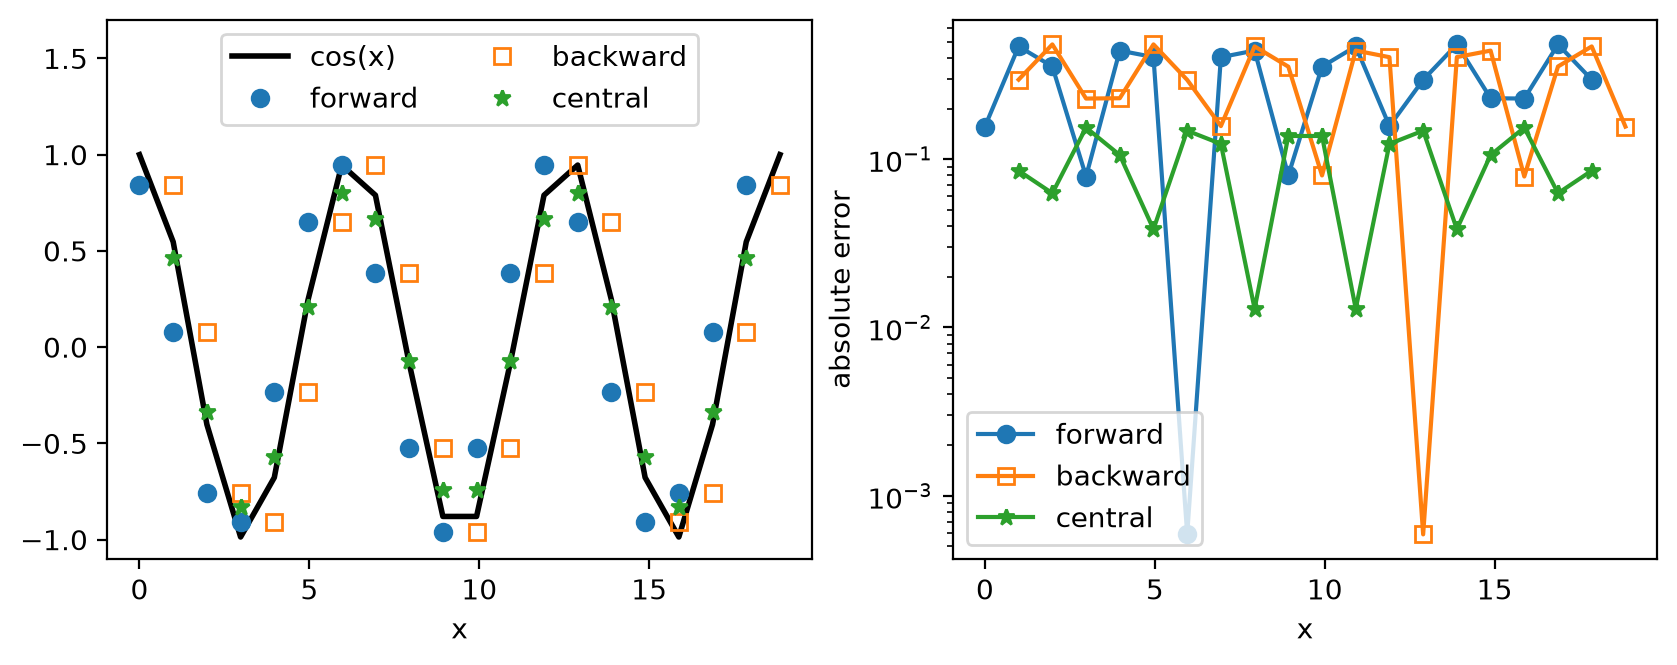

In [17]:
# a static example, N = 20
fd_errors(20)

Run the cell below in Jupyter or Colab to get the slider (it does not appear in the static book). Notice that the central-difference error drops much faster than the forward and backward errors as $N$ grows.

In [18]:
interact(fd_errors, N=IntSlider(value=20, min=10, max=400, step=10));

interactive(children=(IntSlider(value=20, description='N', max=400, min=10, step=10), Output()), _dom_classes=…